# ==========================================
# PROJECT: ZOO ANIMALS - EXPLORATORY DATA ANALYSIS
# ==========================================

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
#Download latest version
path = kagglehub.dataset_download("ulrikthygepedersen/zoo-animals")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'zoo-animals' dataset.
Path to dataset files: /kaggle/input/zoo-animals


In [ ]:
import pandas as pd

df = pd.read_csv("/kaggle/input/zoo-animals/zoo.csv")   # change to your file path
print(df.shape)
df.head()

(101, 18)


,animal,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,b'aardvark',b'true',b'false',b'false',b'true',b'false',b'false',b'true',b'true',b'true',b'true',b'false',b'false',4.0,b'false',b'false',b'true',b'mammal'
1,b'antelope',b'true',b'false',b'false',b'true',b'false',b'false',b'false',b'true',b'true',b'true',b'false',b'false',4.0,b'true',b'false',b'true',b'mammal'
2,b'bass',b'false',b'false',b'true',b'false',b'false',b'true',b'true',b'true',b'true',b'false',b'false',b'true',0.0,b'true',b'false',b'false',b'fish'
3,b'bear',b'true',b'false',b'false',b'true',b'false',b'false',b'true',b'true',b'true',b'true',b'false',b'false',4.0,b'false',b'false',b'true',b'mammal'
4,b'boar',b'true',b'false',b'false',b'true',b'false',b'false',b'true',b'true',b'true',b'true',b'false',b'false',4.0,b'true',b'false',b'true',b'mammal'


In [36]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   animal    101 non-null    object 
 1   hair      101 non-null    object 
 2   feathers  101 non-null    object 
 3   eggs      101 non-null    object 
 4   milk      101 non-null    object 
 5   airborne  101 non-null    object 
 6   aquatic   101 non-null    object 
 7   predator  101 non-null    object 
 8   toothed   101 non-null    object 
 9   backbone  101 non-null    object 
 10  breathes  101 non-null    object 
 11  venomous  101 non-null    object 
 12  fins      101 non-null    object 
 13  legs      101 non-null    float64
 14  tail      101 non-null    object 
 15  domestic  101 non-null    object 
 16  catsize   101 non-null    object 
 17  type      101 non-null    object 
dtypes: float64(1), object(17)
memory usage: 14.3+ KB


In [37]:
df.describe()

,legs
count,101.000000
mean,2.841584
std,2.033385
min,0.000000
25%,2.000000
50%,4.000000
75%,4.000000
max,8.000000


In [38]:
df.isna().sum()

,0
animal,0
hair,0
feathers,0
eggs,0
milk,0
airborne,0
aquatic,0
predator,0
toothed,0
backbone,0


In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df=df.drop_duplicates()

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   animal    101 non-null    object 
 1   hair      101 non-null    object 
 2   feathers  101 non-null    object 
 3   eggs      101 non-null    object 
 4   milk      101 non-null    object 
 5   airborne  101 non-null    object 
 6   aquatic   101 non-null    object 
 7   predator  101 non-null    object 
 8   toothed   101 non-null    object 
 9   backbone  101 non-null    object 
 10  breathes  101 non-null    object 
 11  venomous  101 non-null    object 
 12  fins      101 non-null    object 
 13  legs      101 non-null    float64
 14  tail      101 non-null    object 
 15  domestic  101 non-null    object 
 16  catsize   101 non-null    object 
 17  type      101 non-null    object 
dtypes: float64(1), object(17)
memory usage: 14.3+ KB


##Question 1: How many animals are present in each animal type?

In [ ]:
animals_per_type = df['type'].value_counts().sort_index()
print(animals_per_type)

# Or with animal names listed per type
df.groupby('type')['animal'].agg(['count', list])

type
b'amphibian'        4
b'bird'            20
b'fish'            13
b'insect'           8
b'invertebrate'    10
b'mammal'          41
b'reptile'          5
Name: count, dtype: int64


,count,list
type,,
b'amphibian',4,"[b'frog', b'frog', b'newt', b'toad']"
b'bird',20,"[b'chicken', b'crow', b'dove', b'duck', b'flam..."
b'fish',13,"[b'bass', b'carp', b'catfish', b'chub', b'dogf..."
b'insect',8,"[b'flea', b'gnat', b'honeybee', b'housefly', b..."
b'invertebrate',10,"[b'clam', b'crab', b'crayfish', b'lobster', b'..."
b'mammal',41,"[b'aardvark', b'antelope', b'bear', b'boar', b..."
b'reptile',5,"[b'pitviper', b'seasnake', b'slowworm', b'tort..."


#Question 2: How many animals have hair, feathers, eggs or milk?

Number of animals having each characteristic:
hair : 43
feathers : 20
eggs : 59
milk : 41

Percentage of animals:
hair : 42.6 %
feathers : 19.8 %
eggs : 58.4 %
milk : 40.6 %


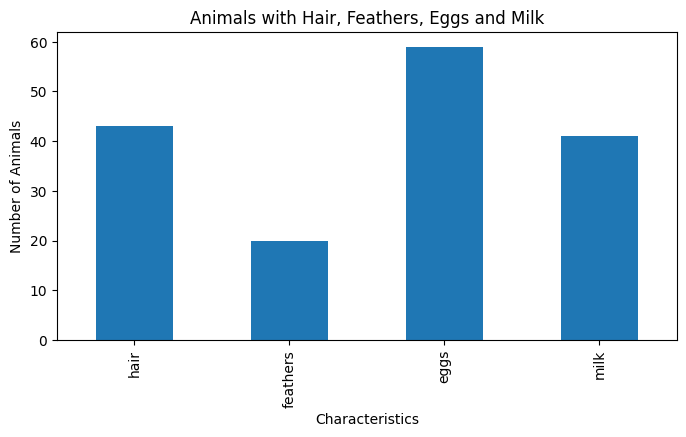

In [ ]:

# Count animals having hair, feathers, eggs or milk

characteristics = ['hair', 'feathers', 'eggs', 'milk']

print("Number of animals having each characteristic:")

for col in characteristics:
    count = (df[col] == "b'true'").sum()
    print(col, ":", count)

# Calculate percentage of animals

print("\nPercentage of animals:")

for col in characteristics:
    percentage = (df[col] == "b'true'").sum() / len(df) * 100
    print(col, ":", round(percentage, 1), "%")

# Optional bar chart

df[characteristics].apply(
    lambda col: col == "b'true'"
).sum().plot(
    kind='bar',
    figsize=(8, 4),
    title='Animals with Hair, Feathers, Eggs and Milk'
)

plt.xlabel("Characteristics")
plt.ylabel("Number of Animals")
plt.show()


#Question 3: Which animal types have the largest number

In [ ]:
type_counts = df['type'].value_counts()
print(type_counts.head(3))                        # top 3
print("Largest type:", type_counts.idxmax(), "->", type_counts.max(), "records")

type
b'mammal'    41
b'bird'      20
b'fish'      13
Name: count, dtype: int64
Largest type: b'mammal' -> 41 records


#Question 4: List animals that are both aquatic and predators.

In [ ]:
aq_pred = df[(df['aquatic'] == "b'true'") & (df['predator'] == "b'true'")]
print("Count:", len(aq_pred))
print(aq_pred['animal'].tolist())

Count: 29
["b'bass'", "b'catfish'", "b'chub'", "b'crab'", "b'crayfish'", "b'dogfish'", "b'dolphin'", "b'frog'", "b'frog'", "b'gull'", "b'herring'", "b'lobster'", "b'mink'", "b'newt'", "b'octopus'", "b'penguin'", "b'pike'", "b'piranha'", "b'platypus'", "b'porpoise'", "b'seal'", "b'sealion'", "b'seasnake'", "b'seawasp'", "b'skimmer'", "b'skua'", "b'starfish'", "b'stingray'", "b'tuna'"]


#Question 5: Find the most common characteristics in the dataset.

Common traits count:
backbone    83
breathes    80
tail        75
toothed     61
eggs        59
predator    56
catsize     44
hair        43
milk        41
aquatic     36
airborne    24
feathers    20
fins        17
domestic    13
venomous     8
dtype: int64

Percentage of animals:
backbone    82.2
breathes    79.2
tail        74.3
toothed     60.4
eggs        58.4
predator    55.4
catsize     43.6
hair        42.6
milk        40.6
aquatic     35.6
airborne    23.8
feathers    19.8
fins        16.8
domestic    12.9
venomous     7.9
dtype: float64

Most common legs value: 4.0


<Axes: title={'center': 'Most common characteristics'}>

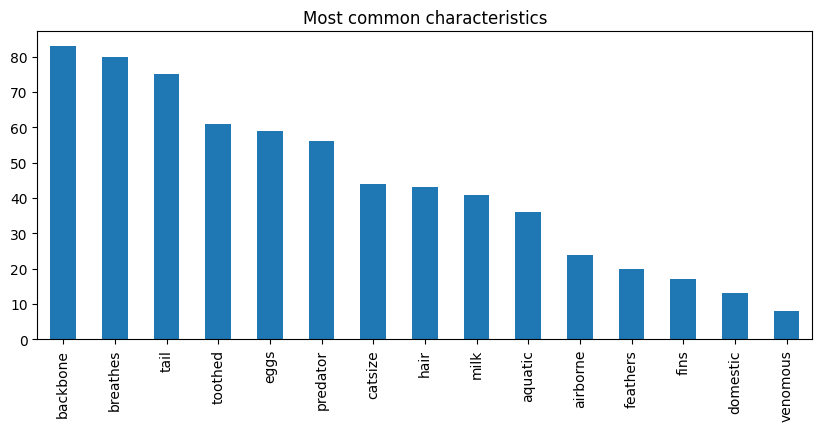

In [ ]:
binary_cols = df.drop(columns=['animal', 'legs', 'type']).columns

# Convert "b'true'"/"b'false'" strings to boolean 1/0 for summation
bool_df = df[binary_cols].apply(lambda col: col == "b'true'")
common = bool_df.sum().sort_values(ascending=False)
print("Common traits count:")
print(common)

# As a percentage of all animals
print("\nPercentage of animals:")
print((common / len(df) * 100).round(1))

# Most common number of legs
print("\nMost common legs value:", df['legs'].mode()[0])

# Optional bar chart
common.plot(kind='bar', figsize=(10, 4), title='Most common characteristics')

##Question 6: Check for missing values and duplicates in the dataset.

In [ ]:
# Missing values
print("Missing values per column:")
print(df.isnull().sum())
print("Total missing:", df.isnull().sum().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())
print(df[df.duplicated(keep=False)])

# Duplicate animal names
print("\nDuplicate animal names:", df['animal'].duplicated().sum())
print(df[df['animal'].duplicated(keep=False)])

# Optional: remove duplicates
# df = df.drop_duplicates()

Missing values per column:
animal      0
hair        0
feathers    0
eggs        0
milk        0
airborne    0
aquatic     0
predator    0
toothed     0
backbone    0
breathes    0
venomous    0
fins        0
legs        0
tail        0
domestic    0
catsize     0
type        0
dtype: int64
Total missing: 0

Duplicate rows: 0
Empty DataFrame
Columns: [animal, hair, feathers, eggs, milk, airborne, aquatic, predator, toothed, backbone, breathes, venomous, fins, legs, tail, domestic, catsize, type]
Index: []

Duplicate animal names: 1
     animal      hair  feathers     eggs      milk  airborne  aquatic  \
25  b'frog'  b'false'  b'false'  b'true'  b'false'  b'false'  b'true'   
26  b'frog'  b'false'  b'false'  b'true'  b'false'  b'false'  b'true'   

   predator  toothed backbone breathes  venomous      fins  legs      tail  \
25  b'true'  b'true'  b'true'  b'true'  b'false'  b'false'   4.0  b'false'   
26  b'true'  b'true'  b'true'  b'true'   b'true'  b'false'   4.0  b'false'   

    dom

The dataset is class-imbalanced. Mammals (41) and Birds (20) make up about 60% of all records, while Reptiles (5) and Amphibians (4) together are under 10%. Any analysis or model built on this data will be dominated by the larger classes.

Eggs, hair and milk are the most common biological traits, and features map closely to classes. Eggs appear in 59 animals, hair in 43, milk in 41, and feathers in 20. Feathers match the Bird class exactly. No animal has all four features, and the platypus is the notable exception, since it has hair, milk and eggs together.

The data is clean, and most animals are air-breathing vertebrates. There are no missing values and no fully duplicate rows (only "frog" repeats by name, with different values). The most common traits are backbone (83), breathes (80) and tail (~75), and the most common leg count is 4.